# Smart Healthcare Data Analysis

## 1. Import libraries

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", 50)

## 2. Read the five CSV files

In [2]:
patients = pd.read_csv(r"C:\Users\HP\Downloads\archive (6)\patients.csv")
doctors = pd.read_csv(r"C:\Users\HP\Downloads\archive (6)\doctors.csv")
appointments = pd.read_csv(r"C:\Users\HP\Downloads\archive (6)\appointments.csv")
treatments = pd.read_csv(r"C:\Users\HP\Downloads\archive (6)\treatments.csv")
billing = pd.read_csv(r"C:\Users\HP\Downloads\archive (6)\billing.csv")

data = {
    "Patients": patients,
    "Doctors": doctors,
    "Appointments": appointments,
    "Treatments": treatments,
    "Billing": billing
}

for name, table in data.items():
    print(f"{name}: {table.shape[0]} rows and {table.shape[1]} columns")

Patients: 50 rows and 11 columns
Doctors: 10 rows and 8 columns
Appointments: 200 rows and 7 columns
Treatments: 200 rows and 6 columns
Billing: 200 rows and 7 columns


## 3. Basic data checks

In [3]:
for name, table in data.items():
    print(f"\n{name}")
    print("Duplicate rows:", table.duplicated().sum())
    display(table.isna().sum().rename("Missing values").to_frame())


Patients
Duplicate rows: 0


,Missing values
patient_id,0
first_name,0
last_name,0
gender,0
date_of_birth,0
contact_number,0
address,0
registration_date,0
insurance_provider,0
insurance_number,0



Doctors
Duplicate rows: 0


,Missing values
doctor_id,0
first_name,0
last_name,0
specialization,0
phone_number,0
years_experience,0
hospital_branch,0
email,0



Appointments
Duplicate rows: 0


,Missing values
appointment_id,0
patient_id,0
doctor_id,0
appointment_date,0
appointment_time,0
reason_for_visit,0
status,0



Treatments
Duplicate rows: 0


,Missing values
treatment_id,0
appointment_id,0
treatment_type,0
description,0
cost,0
treatment_date,0



Billing
Duplicate rows: 0


,Missing values
bill_id,0
patient_id,0
treatment_id,0
bill_date,0
amount,0
payment_method,0
payment_status,0


In [30]:

for name, table in data.items():
    print(f"\n{name} — first five rows")
    display(table.head())


Patients — first five rows


,patient_id,first_name,last_name,gender,date_of_birth,contact_number,address,registration_date,insurance_provider,insurance_number,email
0,P001,David,Williams,F,1955-06-04,6939585183,789 Pine Rd,2022-06-23,WellnessCorp,INS840674,david.williams@mail.com
1,P002,Emily,Smith,F,1984-10-12,8228188767,321 Maple Dr,2022-01-15,PulseSecure,INS354079,emily.smith@mail.com
2,P003,Laura,Jones,M,1977-08-21,8397029847,321 Maple Dr,2022-02-07,PulseSecure,INS650929,laura.jones@mail.com
3,P004,Michael,Johnson,F,1981-02-20,9019443432,123 Elm St,2021-03-02,HealthIndia,INS789944,michael.johnson@mail.com
4,P005,David,Wilson,M,1960-06-23,7734463155,123 Elm St,2021-09-29,MedCare Plus,INS788105,david.wilson@mail.com



Doctors — first five rows


,doctor_id,first_name,last_name,specialization,phone_number,years_experience,hospital_branch,email
0,D001,David,Taylor,Dermatology,8322010158,17,Westside Clinic,dr.david.taylor@hospital.com
1,D002,Jane,Davis,Pediatrics,9004382050,24,Eastside Clinic,dr.jane.davis@hospital.com
2,D003,Jane,Smith,Pediatrics,8737740598,19,Eastside Clinic,dr.jane.smith@hospital.com
3,D004,David,Jones,Pediatrics,6594221991,28,Central Hospital,dr.david.jones@hospital.com
4,D005,Sarah,Taylor,Dermatology,9118538547,26,Central Hospital,dr.sarah.taylor@hospital.com



Appointments — first five rows


,appointment_id,patient_id,doctor_id,appointment_date,appointment_time,reason_for_visit,status
0,A001,P034,D009,2023-08-09,15:15:00,Therapy,Scheduled
1,A002,P032,D004,2023-06-09,14:30:00,Therapy,No-show
2,A003,P048,D004,2023-06-28,8:00:00,Consultation,Cancelled
3,A004,P025,D006,2023-09-01,9:15:00,Consultation,Cancelled
4,A005,P040,D003,2023-07-06,12:45:00,Emergency,No-show



Treatments — first five rows


,treatment_id,appointment_id,treatment_type,description,cost,treatment_date
0,T001,A001,Chemotherapy,Basic screening,3941.97,2023-08-09
1,T002,A002,MRI,Advanced protocol,4158.44,2023-06-09
2,T003,A003,MRI,Standard procedure,3731.55,2023-06-28
3,T004,A004,MRI,Basic screening,4799.86,2023-09-01
4,T005,A005,ECG,Standard procedure,582.05,2023-07-06



Billing — first five rows


,bill_id,patient_id,treatment_id,bill_date,amount,payment_method,payment_status
0,B001,P034,T001,2023-08-09,3941.97,Insurance,Pending
1,B002,P032,T002,2023-06-09,4158.44,Insurance,Paid
2,B003,P048,T003,2023-06-28,3731.55,Insurance,Paid
3,B004,P025,T004,2023-09-01,4799.86,Insurance,Failed
4,B005,P040,T005,2023-07-06,582.05,Credit Card,Pending


## 4. Prepare dates and numeric columns

In [5]:
# we will Convert date columns so that monthly charts work correctly.
date_columns = {
    "patients": ["date_of_birth", "registration_date"],
    "appointments": ["appointment_date"],
    "treatments": ["treatment_date"],
    "billing": ["bill_date"]
}
frames = {
    "patients": patients,
    "appointments": appointments,
    "treatments": treatments,
    "billing": billing
}

for table_name, columns in date_columns.items():
    for column in columns:
        if column in frames[table_name].columns:
            frames[table_name][column] = pd.to_datetime(
                frames[table_name][column], errors="coerce"
            )

if "years_experience" in doctors.columns:
    doctors["years_experience"] = pd.to_numeric(doctors["years_experience"], errors="coerce")
if "cost" in treatments.columns:
    treatments["cost"] = pd.to_numeric(treatments["cost"], errors="coerce")
if "amount" in billing.columns:
    billing["amount"] = pd.to_numeric(billing["amount"], errors="coerce")

print("Date and numeric columns are ready.")

Date and numeric columns are ready.


## 5. Patient analysis

These charts look at the gender mix, insurance providers and patient registration trend.

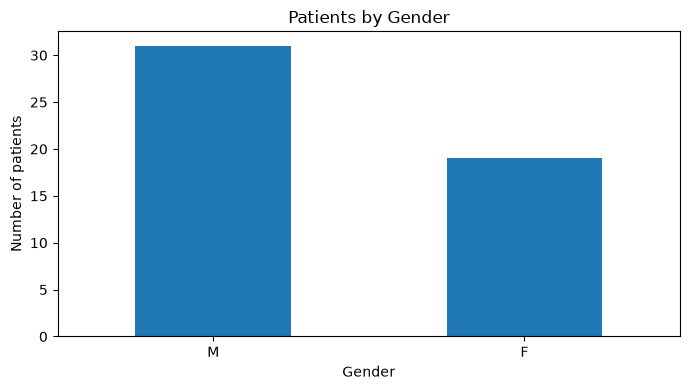

In [6]:
# Chart 1: Number of patients by gender
gender_counts = patients["gender"].fillna("Unknown").value_counts()
gender_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Patients by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

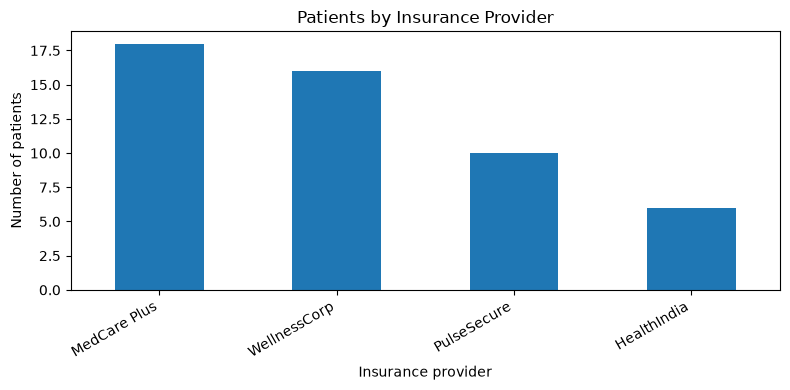

In [7]:
# Chart 2: Patients by insurance provider
insurance_counts = patients["insurance_provider"].fillna("Unknown").value_counts()
insurance_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Patients by Insurance Provider")
plt.xlabel("Insurance provider")
plt.ylabel("Number of patients")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

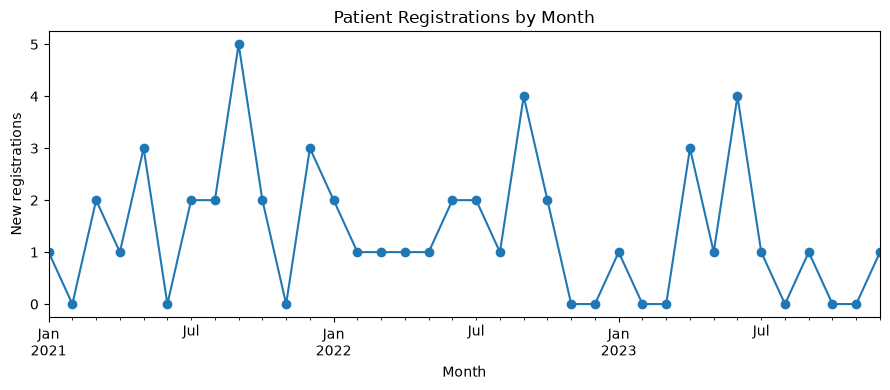

In [8]:
# Chart 3: Patient registrations by month
registration_data = patients.dropna(subset=["registration_date"]).copy()
if not registration_data.empty:
    monthly_registrations = (
        registration_data.set_index("registration_date")
        .resample("MS").size()
    )
    monthly_registrations.plot(marker="o", figsize=(9, 4))
    plt.title("Patient Registrations by Month")
    plt.xlabel("Month")
    plt.ylabel("New registrations")
    plt.tight_layout()
    plt.show()
else:
    print("No valid registration dates were found.")

## 6. Doctor analysis

These charts show the number of doctors by specialization and branch, plus the spread of their experience.

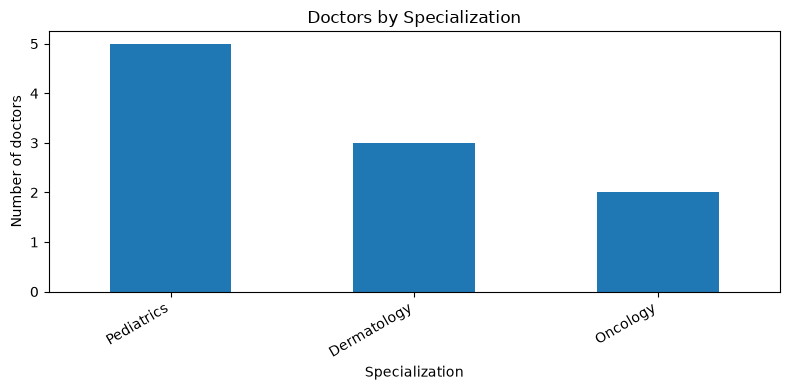

In [9]:
# Chart 1: Doctors by specialization
specialization_counts = doctors["specialization"].fillna("Unknown").value_counts()
specialization_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Doctors by Specialization")
plt.xlabel("Specialization")
plt.ylabel("Number of doctors")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

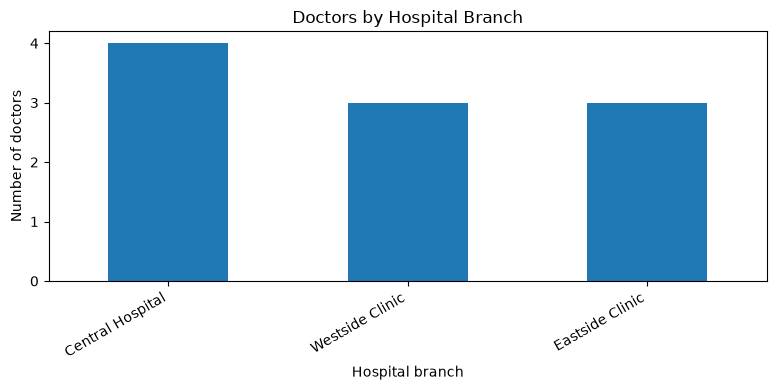

In [10]:
# Chart 2: Doctors by hospital branch
if "hospital_branch" in doctors.columns:
    branch_counts = doctors["hospital_branch"].fillna("Unknown").value_counts()
    branch_counts.plot(kind="bar", figsize=(8, 4))
    plt.title("Doctors by Hospital Branch")
    plt.xlabel("Hospital branch")
    plt.ylabel("Number of doctors")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("The hospital_branch column is not available.")

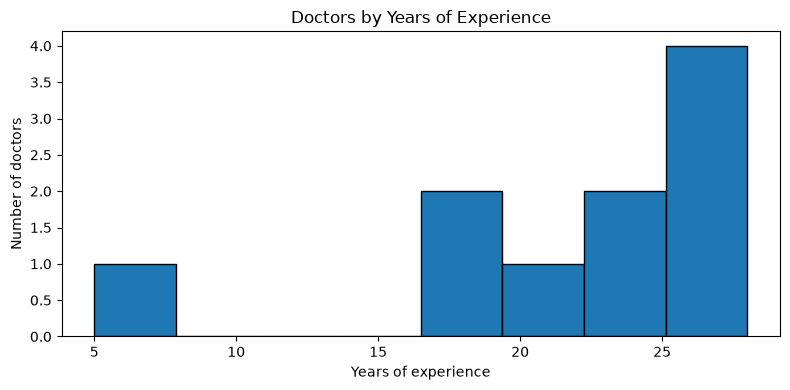

In [11]:
# Chart 3: Distribution of doctors' years of experience
if "years_experience" in doctors.columns:
    experience = doctors["years_experience"].dropna()
    if not experience.empty:
        experience.plot(kind="hist", bins=8, edgecolor="black", figsize=(8, 4))
        plt.title("Doctors by Years of Experience")
        plt.xlabel("Years of experience")
        plt.ylabel("Number of doctors")
        plt.tight_layout()
        plt.show()
    else:
        print("No valid experience values were found.")
else:
    print("The years_experience column is not available.")

## 7. Appointment analysis

These charts summarise appointment status, reasons for visits, monthly activity and appointment workload by doctor.

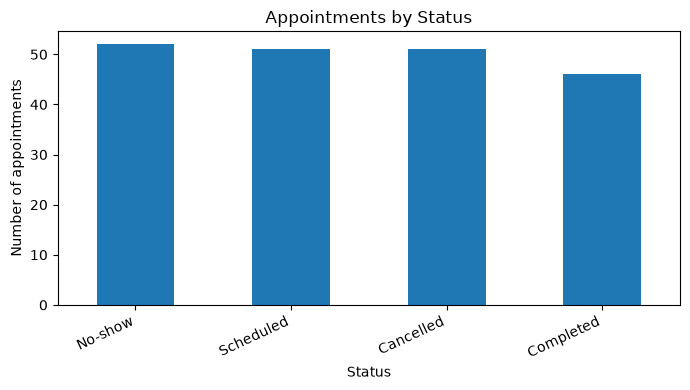

In [12]:
# Chart 1: Appointments by status
status_counts = appointments["status"].fillna("Unknown").value_counts()
status_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Appointments by Status")
plt.xlabel("Status")
plt.ylabel("Number of appointments")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

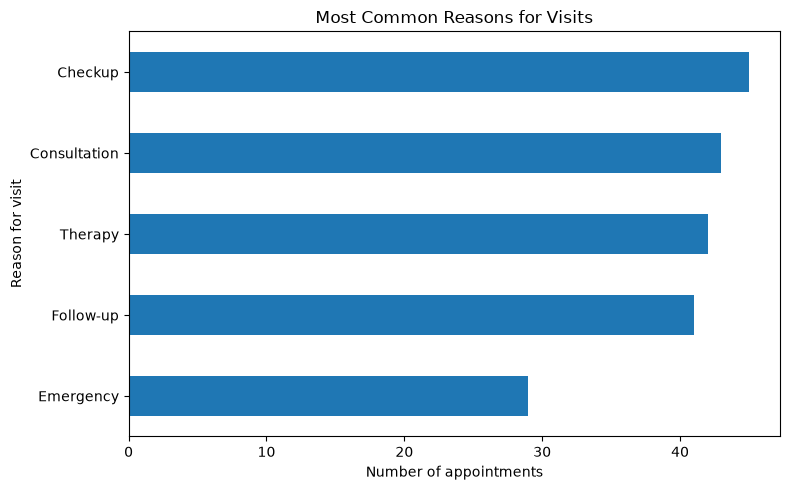

In [13]:
# Chart 2: Most common reasons for visits (top 10)
reason_counts = appointments["reason_for_visit"].fillna("Unknown").value_counts().head(10)
reason_counts.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Most Common Reasons for Visits")
plt.xlabel("Number of appointments")
plt.ylabel("Reason for visit")
plt.tight_layout()
plt.show()

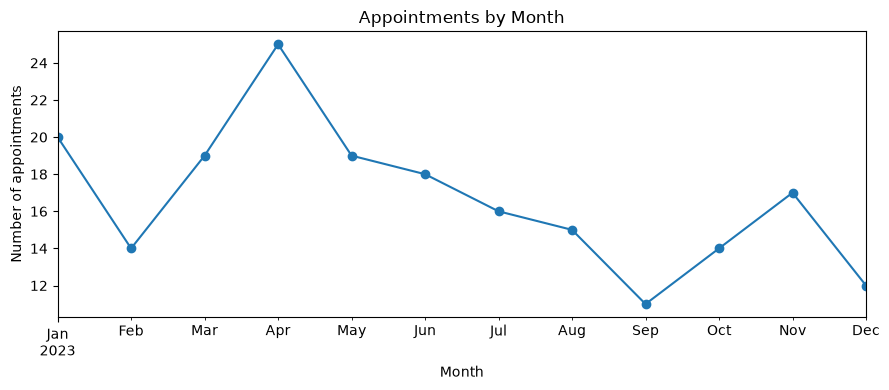

In [14]:
# Chart 3: Appointments by month
appointment_dates = appointments.dropna(subset=["appointment_date"]).copy()
if not appointment_dates.empty:
    monthly_appointments = (
        appointment_dates.set_index("appointment_date").resample("MS").size()
    )
    monthly_appointments.plot(marker="o", figsize=(9, 4))
    plt.title("Appointments by Month")
    plt.xlabel("Month")
    plt.ylabel("Number of appointments")
    plt.tight_layout()
    plt.show()
else:
    print("No valid appointment dates were found.")

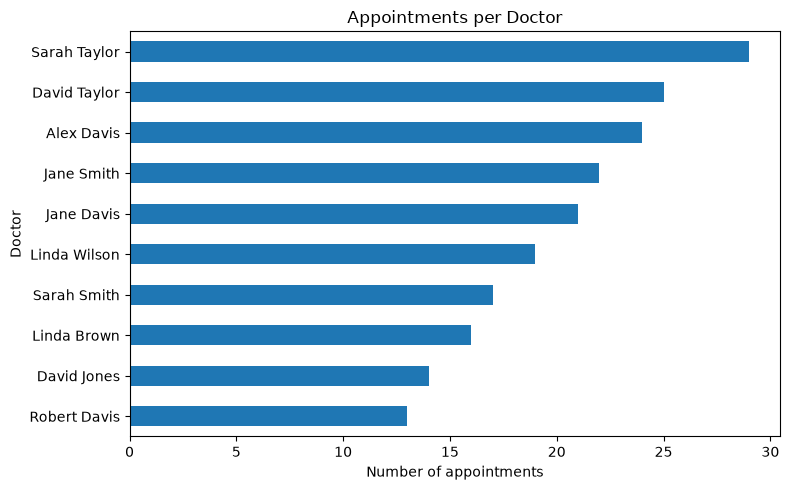

In [15]:
# Chart 4: Number of appointments handled by each doctor
appointment_counts = appointments["doctor_id"].value_counts().rename_axis("doctor_id").reset_index(name="appointment_count")
doctor_names = doctors[["doctor_id", "first_name", "last_name"]].copy()
doctor_names["doctor_name"] = (
    doctor_names["first_name"].fillna("").astype(str) + " " +
    doctor_names["last_name"].fillna("").astype(str)
).str.strip()
appointment_counts = appointment_counts.merge(
    doctor_names[["doctor_id", "doctor_name"]], on="doctor_id", how="left"
)
appointment_counts["doctor_name"] = appointment_counts["doctor_name"].fillna(
    appointment_counts["doctor_id"].astype(str)
)
chart_data = appointment_counts.sort_values("appointment_count")
chart_data.plot(
    kind="barh", x="doctor_name", y="appointment_count",
    legend=False, figsize=(8, 5)
)
plt.title("Appointments per Doctor")
plt.xlabel("Number of appointments")
plt.ylabel("Doctor")
plt.tight_layout()
plt.show()

## 8. Treatment analysis

These charts compare treatment types, treatment costs and the average cost for each type.

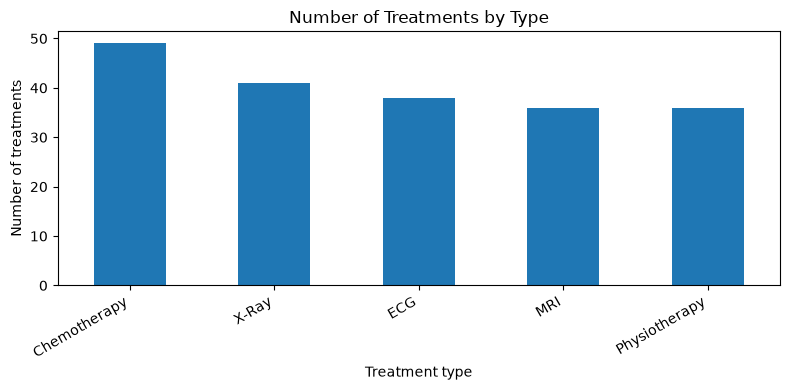

In [16]:
# Chart 1: Number of treatments by type
treatment_counts = treatments["treatment_type"].fillna("Unknown").value_counts()
treatment_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Number of Treatments by Type")
plt.xlabel("Treatment type")
plt.ylabel("Number of treatments")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

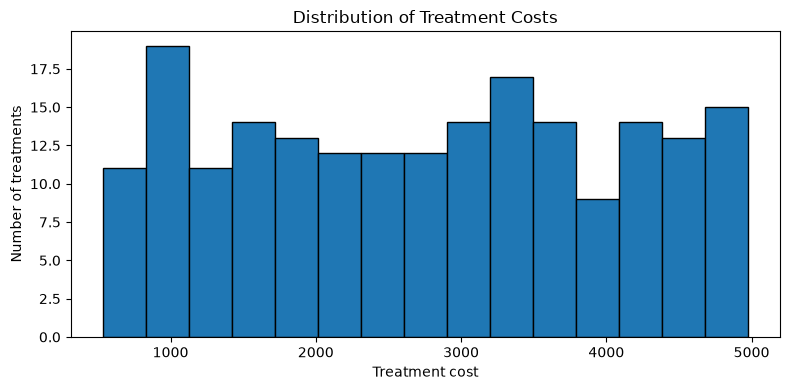

In [17]:
# Chart 2: Distribution of treatment costs
treatment_costs = treatments["cost"].dropna()
if not treatment_costs.empty:
    treatment_costs.plot(kind="hist", bins=15, edgecolor="black", figsize=(8, 4))
    plt.title("Distribution of Treatment Costs")
    plt.xlabel("Treatment cost")
    plt.ylabel("Number of treatments")
    plt.tight_layout()
    plt.show()
else:
    print("No valid treatment costs were found.")

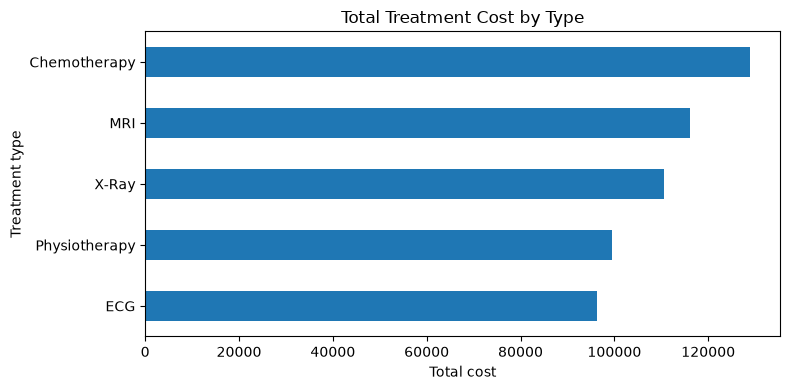

In [18]:
# Chart 3: Total treatment cost by type
total_cost_by_type = (
    treatments.groupby("treatment_type", dropna=False)["cost"]
    .sum().sort_values()
)
total_cost_by_type.index = total_cost_by_type.index.fillna("Unknown")
total_cost_by_type.plot(kind="barh", figsize=(8, 4))
plt.title("Total Treatment Cost by Type")
plt.xlabel("Total cost")
plt.ylabel("Treatment type")
plt.tight_layout()
plt.show()

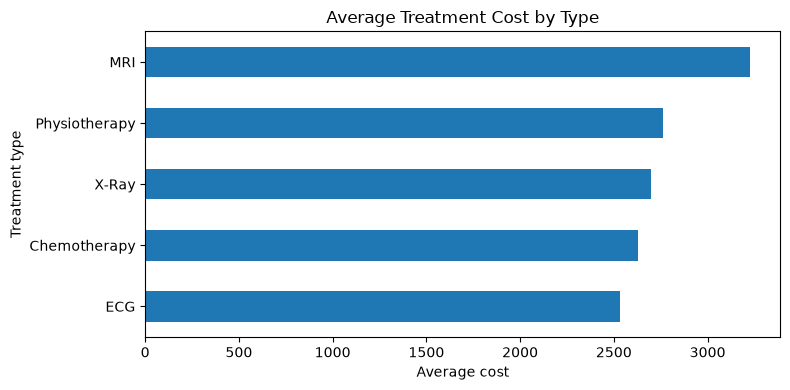

In [19]:
# Chart 4: Average treatment cost by type
average_cost_by_type = (
    treatments.groupby("treatment_type", dropna=False)["cost"]
    .mean().sort_values()
)
average_cost_by_type.index = average_cost_by_type.index.fillna("Unknown")
average_cost_by_type.plot(kind="barh", figsize=(8, 4))
plt.title("Average Treatment Cost by Type")
plt.xlabel("Average cost")
plt.ylabel("Treatment type")
plt.tight_layout()
plt.show()

## 9. Billing analysis

These charts look at payment status, payment method, bill amounts and monthly billing totals. Total billed amount is not necessarily the same as money collected.

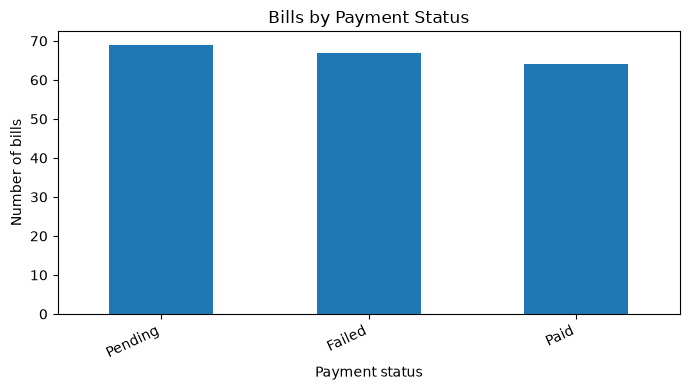

In [20]:
# Chart 1: Bills by payment status
payment_status_counts = billing["payment_status"].fillna("Unknown").value_counts()
payment_status_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Bills by Payment Status")
plt.xlabel("Payment status")
plt.ylabel("Number of bills")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

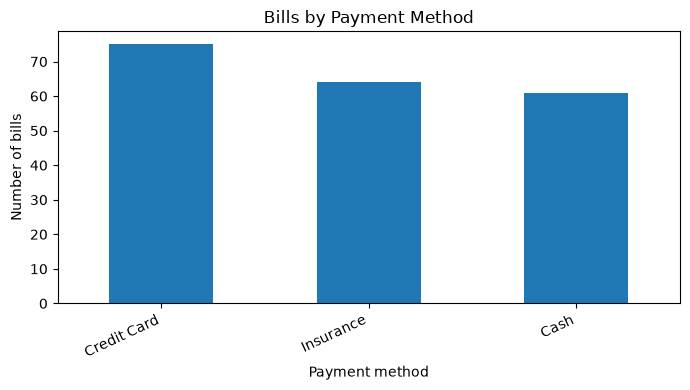

In [21]:
# Chart 2: Bills by payment method
payment_method_counts = billing["payment_method"].fillna("Unknown").value_counts()
payment_method_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Bills by Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Number of bills")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

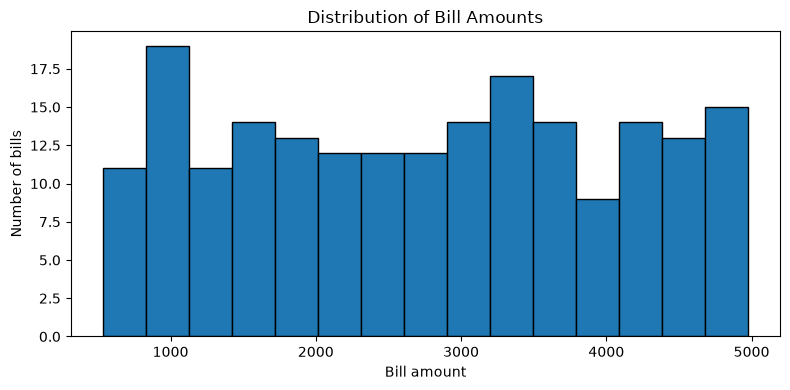

In [22]:
# Chart 3: Distribution of bill amounts
bill_amounts = billing["amount"].dropna()
if not bill_amounts.empty:
    bill_amounts.plot(kind="hist", bins=15, edgecolor="black", figsize=(8, 4))
    plt.title("Distribution of Bill Amounts")
    plt.xlabel("Bill amount")
    plt.ylabel("Number of bills")
    plt.tight_layout()
    plt.show()
else:
    print("No valid bill amounts were found.")

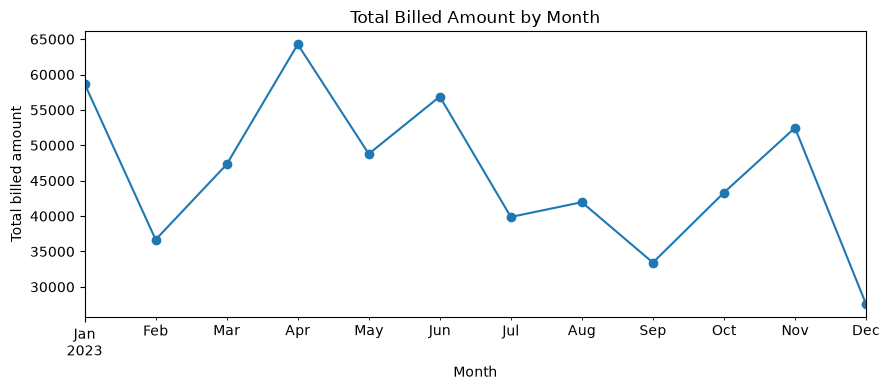

In [23]:
# Chart 4: Total billed amount by month
bill_dates = billing.dropna(subset=["bill_date"]).copy()
if not bill_dates.empty:
    monthly_billing = bill_dates.set_index("bill_date")["amount"].resample("MS").sum()
    monthly_billing.plot(marker="o", figsize=(9, 4))
    plt.title("Total Billed Amount by Month")
    plt.xlabel("Month")
    plt.ylabel("Total billed amount")
    plt.tight_layout()
    plt.show()
else:
    print("No valid bill dates were found.")

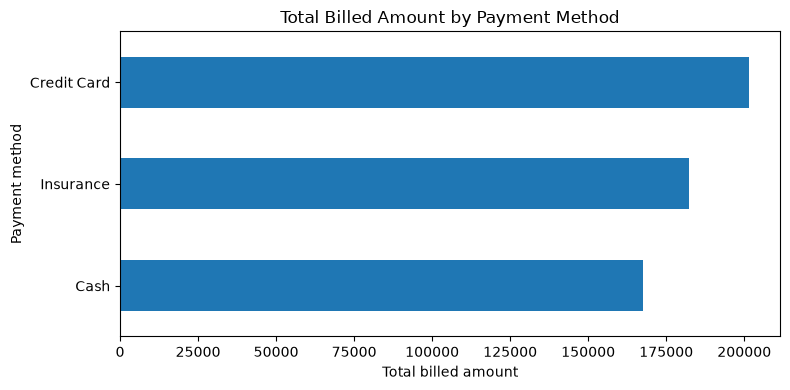

In [24]:
# Chart 5: Total billed amount by payment method
amount_by_method = (
    billing.groupby("payment_method", dropna=False)["amount"]
    .sum().sort_values()
)
amount_by_method.index = amount_by_method.index.fillna("Unknown")
amount_by_method.plot(kind="barh", figsize=(8, 4))
plt.title("Total Billed Amount by Payment Method")
plt.xlabel("Total billed amount")
plt.ylabel("Payment method")
plt.tight_layout()
plt.show()

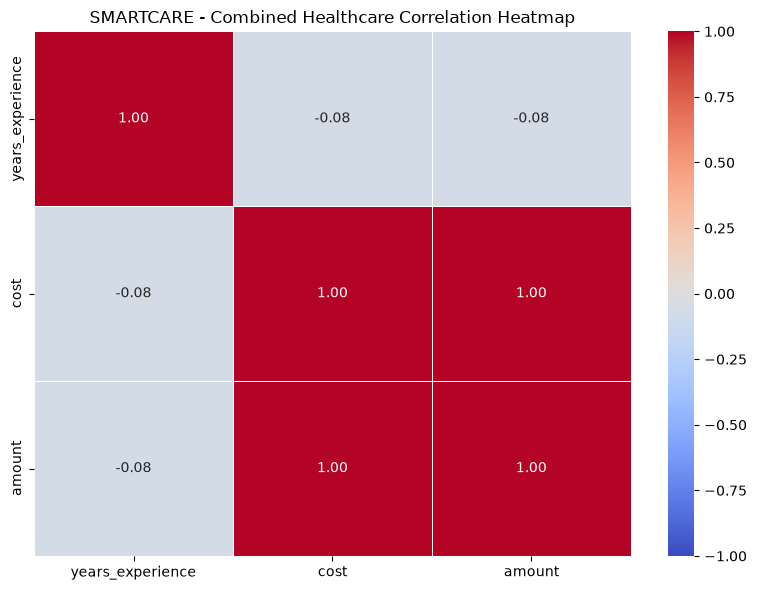

In [29]:
healthcare = (
    appointments
    .merge(patients, on="patient_id", how="left", suffixes=("", "_patient"))
    .merge(doctors, on="doctor_id", how="left", suffixes=("", "_doctor"))
    .merge(treatments, on="appointment_id", how="left")
    .merge(billing, on=["patient_id", "treatment_id"], how="left")
)

# Select meaningful numerical columns
columns = [
    "years_experience",
    "cost",
    "amount"
]

numeric_data = healthcare[columns].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate correlations
correlation = numeric_data.corr()

# Draw the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("SMARTCARE - Combined Healthcare Correlation Heatmap")
plt.tight_layout()
plt.show()

## 10. Quick summary

In [25]:
print("SMART HEALTHCARE — DATA SUMMARY")
print("-" * 36)
print("Patients:", len(patients))
print("Doctors:", len(doctors))
print("Appointments:", len(appointments))
print("Treatment records:", len(treatments))
print("Bills:", len(billing))
print("Treatment types:", treatments["treatment_type"].nunique())
print("Total treatment cost:", round(treatments["cost"].sum(), 2))
print("Total billed amount:", round(billing["amount"].sum(), 2))
print("\nMost common appointment status:")
print(appointments["status"].mode().iloc[0] if not appointments["status"].mode().empty else "Not available")
print("Most common payment status:")
print(billing["payment_status"].mode().iloc[0] if not billing["payment_status"].mode().empty else "Not available")

SMART HEALTHCARE — DATA SUMMARY
------------------------------------
Patients: 50
Doctors: 10
Appointments: 200
Treatment records: 200
Bills: 200
Treatment types: 5
Total treatment cost: 551249.85
Total billed amount: 551249.85

Most common appointment status:
No-show
Most common payment status:
Pending
